# Battery State-of-Health (SOH) Estimation: CNN + GRU

Dataset: MATR / Severson et al. 2019 (124 LFP cells, 3 batches). The model is trained from scratch.

**How to run:** put the three `.mat` files next to this notebook, set the file names in Section 1, then run all cells from top to bottom. Each section after the loader reads from variables or from the cache, so it can be re-run on its own.

| Section | What it does |
|---|---|
| 1 | Settings |
| 2 | Imports |
| 3 | Read the `.mat` files (cached after the first run) |
| 4 | Merge split cells, drop bad cells, clean cycles |
| 5 | Features, train/val/test split, normalisation, history windows |
| 6 | Ridge baseline |
| 7 | CNN + GRU model and training |
| 8 | Evaluation and plots |
| 9 | Real-time estimator demo |
| 10 | Timing summary |

`SOH = QDischarge / 1.1 Ah`. In the real-time setting, SOH at cycle k is estimated using only cycles up to k.

In [1]:
pip install -q numpy pandas h5py scikit-learn matplotlib tqdm ipywidgets torch

Note: you may need to restart the kernel to use updated packages.


## 1. Settings

In [2]:
DATA_DIR = "."

BATCH1_FILE = "2017-05-12_batchdata_updated_struct_errorcorrect.mat"
BATCH2_FILE = "2017-06-30_batchdata_updated_struct_errorcorrect.mat"
BATCH3_FILE = "2018-04-12_batchdata_updated_struct_errorcorrect.mat"

OUT_DIR = "soh_outputs"
FORCE_RELOAD = False     # True: ignore caches and re-read the .mat files
QUICK_TEST = False       # True: 3 cells per batch and 2 epochs, for a smoke test

# Partial discharge window. A wide window contains most of the capacity,
# which makes the task close to reading the answer off the curve.
V_HIGH, V_LOW = 3.3, 3.1
N_POINTS = 100
HISTORY = 10
SCALARS = ["IR", "Tavg", "Tmin", "Tmax", "chargetime"]

BATCH_SIZE = 256
EPOCHS = 2 if QUICK_TEST else 60
PATIENCE = 10
LR = 1e-3
WEIGHT_DECAY = 1e-4
N_VAL = 8
SEED = 42

## 2. Imports

In [3]:
import os, time, pickle, copy, json, warnings
from pathlib import Path
from collections import deque

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(SEED)

OUT = Path(OUT_DIR)
CACHE = OUT / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
SUFFIX = "_quick" if QUICK_TEST else ""

V_GRID = np.linspace(3.6, 2.0, 1000)    # voltage grid of Qdlin / Tdlin
NOMINAL_AH = 1.1
EOL_SOH = 0.80
TIMES = {}

## 3. Read the .mat files

In [4]:
import h5py

BATCH_FILES = {
    "b1": (BATCH1_FILE, "2017-05-12"),
    "b2": (BATCH2_FILE, "2017-06-30"),
    "b3": (BATCH3_FILE, "2018-04-12"),
}
SUMMARY_FIELDS = {"QDischarge": "QD", "QCharge": "QC", "IR": "IR", "Tavg": "Tavg",
                  "Tmin": "Tmin", "Tmax": "Tmax", "chargetime": "chargetime"}


def find_file(fname, prefix):
    path = Path(DATA_DIR) / fname
    if path.exists():
        return path
    hits = sorted(Path(DATA_DIR).glob(prefix + "*.mat"))
    if hits:
        print(f"'{fname}' not found, using '{hits[0].name}'")
        return hits[0]
    raise FileNotFoundError(f"no '{fname}' or '{prefix}*.mat' in '{Path(DATA_DIR).resolve()}'")


def refs(ds):
    return np.asarray(ds[()]).ravel()


def read_num(f, ref):
    obj = f[ref]
    if obj.attrs.get("MATLAB_empty", 0):
        return np.array([], dtype=float)
    return np.asarray(obj[()], dtype=float).ravel()


def read_str(f, ref):
    obj = f[ref]
    if obj.attrs.get("MATLAB_empty", 0):
        return ""
    return "".join(chr(int(c)) for c in np.asarray(obj[()]).ravel())


def load_batch_file(path, tag, max_cells=None):
    cells = {}
    n_grid = len(V_GRID)
    with h5py.File(path, "r") as f:
        batch = f["batch"]
        s_refs, c_refs = refs(batch["summary"]), refs(batch["cycles"])
        p_refs = refs(batch["policy_readable"]) if "policy_readable" in batch else None
        n_cells = len(s_refs) if max_cells is None else min(max_cells, len(s_refs))
        for i in tqdm(range(n_cells), desc=f"{tag}: {path.name}"):
            sgrp = f[s_refs[i]]
            summary = {our: np.asarray(sgrp[mat][()], dtype=float).ravel()
                       for mat, our in SUMMARY_FIELDS.items() if mat in sgrp}
            cgrp = f[c_refs[i]]
            q_refs, t_refs = refs(cgrp["Qdlin"]), refs(cgrp["Tdlin"])
            n_cyc = len(q_refs)
            Q = np.full((n_cyc, n_grid), np.nan, dtype=np.float32)
            T = np.full((n_cyc, n_grid), np.nan, dtype=np.float32)
            for j in range(n_cyc):
                q, t = read_num(f, q_refs[j]), read_num(f, t_refs[j])
                if q.size == n_grid:
                    Q[j] = q
                if t.size == n_grid:
                    T[j] = t
            policy = read_str(f, p_refs[i]).strip() if p_refs is not None else ""
            cells[f"{tag}c{i}"] = {"cell_id": f"{tag}c{i}", "batch": tag, "policy": policy,
                                   "summary": summary, "Qdlin": Q, "Tdlin": T}
    return cells


def load_batch_cached(tag):
    cache = CACHE / f"raw_{tag}{SUFFIX}.pkl"
    if cache.exists() and not FORCE_RELOAD:
        print(f"{tag}: loaded from cache")
        with open(cache, "rb") as fh:
            return pickle.load(fh)
    fname, prefix = BATCH_FILES[tag]
    cells = load_batch_file(find_file(fname, prefix), tag, 3 if QUICK_TEST else None)
    with open(cache, "wb") as fh:
        pickle.dump(cells, fh, protocol=pickle.HIGHEST_PROTOCOL)
    return cells


t0 = time.time()
raw = {tag: load_batch_cached(tag) for tag in BATCH_FILES}
TIMES["1_load_mat"] = time.time() - t0
print({k: len(v) for k, v in raw.items()}, f"cells loaded in {TIMES['1_load_mat'] / 60:.1f} min")

b1: loaded from cache
b2: loaded from cache
b3: loaded from cache
{'b1': 46, 'b2': 48, 'b3': 46} cells loaded in 0.0 min


## 4. Merge, remove bad cells, clean cycles

In [5]:
# Same fixes as the dataset authors: 5 batch-1 cells continue in batch 2, 11 cells are unusable.
MERGE_MAP = {"b2c7": "b1c0", "b2c8": "b1c1", "b2c9": "b1c2", "b2c15": "b1c3", "b2c16": "b1c4"}
BAD_CELLS = ["b1c8", "b1c10", "b1c12", "b1c13", "b1c22",
             "b3c2", "b3c23", "b3c32", "b3c37", "b3c42", "b3c43"]

# only the curve points inside the voltage window (plus a small margin) must be valid
WIN_COLS = np.where((V_GRID <= V_HIGH + 0.02) & (V_GRID >= V_LOW - 0.02))[0]


def n_rows(c):
    return min(len(c["summary"]["QD"]), c["Qdlin"].shape[0], c["Tdlin"].shape[0])


def merge_cells(raw):
    b1, b2, b3 = dict(raw["b1"]), dict(raw["b2"]), dict(raw["b3"])
    log = []
    for k2, k1 in MERGE_MAP.items():
        if k1 not in b1 or k2 not in b2:
            log.append(f"skip {k2} -> {k1}: not found")
            continue
        c1, c2 = b1[k1], b2.pop(k2)
        n1, n2 = n_rows(c1), n_rows(c2)
        summary = {k: np.concatenate([c1["summary"][k][:n1], c2["summary"][k][:n2]])
                   for k in c1["summary"] if k in c2["summary"]}
        b1[k1] = {**c1, "summary": summary,
                  "Qdlin": np.concatenate([c1["Qdlin"][:n1], c2["Qdlin"][:n2]]),
                  "Tdlin": np.concatenate([c1["Tdlin"][:n1], c2["Tdlin"][:n2]])}
        log.append(f"merged {k2} ({n2} cycles) onto {k1} ({n1} cycles)")
    cells = {**b1, **b2, **b3}
    for k in BAD_CELLS:
        cells.pop(k, None)
    return cells, log


def clean_cell(c, qd_min=0.5, qd_max=1.2, spike_window=9, spike_tol=0.02):
    n = n_rows(c)
    df = pd.DataFrame({k: v[:n] for k, v in c["summary"].items()})
    df.insert(0, "cycle", np.arange(n))
    Q, T = c["Qdlin"][:n], c["Tdlin"][:n]

    keep = np.ones(n, dtype=bool)
    keep[0] = False                                   # formation cycle
    qd = df["QD"].values
    keep &= np.isfinite(qd) & (qd >= qd_min) & (qd <= qd_max)

    Qw, Tw = Q[:, WIN_COLS], T[:, WIN_COLS]
    bad_curve = (~np.isfinite(Qw).all(axis=1) | ~np.isfinite(Tw).all(axis=1)
                 | (np.nanmax(np.abs(Qw), axis=1) == 0))
    keep &= ~bad_curve

    qk = df.loc[keep, "QD"]
    med = qk.rolling(spike_window, center=True, min_periods=1).median()
    keep[qk.index[((qk - med).abs() > spike_tol).values]] = False

    df = df.loc[keep].reset_index(drop=True)
    df["SOH"] = df["QD"] / NOMINAL_AH

    # cycle life = first cycle at or below 80% SOH; if the recording stops before that,
    # the last recorded cycle is used and the cell is flagged
    below = np.where(df["SOH"].values <= EOL_SOH)[0]
    reached = below.size > 0
    cycles = df["cycle"].values
    life = float(cycles[below[0]]) if reached else float(cycles[-1])

    return {"cell_id": c["cell_id"], "batch": c["batch"], "policy": c["policy"],
            "cycle_life": life, "reached_eol": bool(reached), "summary": df,
            "Qdlin": np.ascontiguousarray(Q[keep]), "Tdlin": np.ascontiguousarray(T[keep])}


def cell_key(cid):
    b, c = cid[1:].split("c")
    return int(b), int(c)


t0 = time.time()
clean_cache = CACHE / f"cells_clean_v2{SUFFIX}_{V_HIGH}_{V_LOW}.pkl"
if clean_cache.exists() and not FORCE_RELOAD:
    with open(clean_cache, "rb") as fh:
        cells = pickle.load(fh)
    print("cleaned cells loaded from cache")
else:
    merged, merge_log = merge_cells(raw)
    mismatch = [k for k, c in merged.items() if len(c["summary"]["QD"]) != c["Qdlin"].shape[0]]
    print(f"cells where summary rows != curve rows: {len(mismatch)} of {len(merged)}")
    cells = {k: clean_cell(merged[k]) for k in sorted(merged, key=cell_key)}
    with open(clean_cache, "wb") as fh:
        pickle.dump(cells, fh, protocol=pickle.HIGHEST_PROTOCOL)
    print("\n".join(merge_log))

per_batch = pd.Series([c["batch"] for c in cells.values()]).value_counts().sort_index()
print("cells per batch:", per_batch.to_dict(), "| total:", len(cells), "(full dataset: 41 + 43 + 40 = 124)")
print("cycles kept:", sum(len(c["summary"]) for c in cells.values()))
assert len(cells) > 0 and all(len(c["summary"]) > HISTORY for c in cells.values()), \
    "a cell has too few clean cycles, check the .mat files and settings"

life = pd.Series({k: c["cycle_life"] for k, c in cells.items()})
reached = pd.Series({k: c["reached_eol"] for k, c in cells.items()})
print(f"cycle life: min {life.min():.0f}, median {life.median():.0f}, max {life.max():.0f}")
print(f"cells that reach 80% SOH in the data: {reached.sum()} of {len(cells)} "
      "(for the rest, the last recorded cycle is used)")
TIMES["2_clean"] = time.time() - t0

cells where summary rows != curve rows: 0 of 124
merged b2c7 (662 cycles) onto b1c0 (1189 cycles)
merged b2c8 (981 cycles) onto b1c1 (1178 cycles)
merged b2c9 (1060 cycles) onto b1c2 (1176 cycles)
merged b2c15 (208 cycles) onto b1c3 (1225 cycles)
merged b2c16 (482 cycles) onto b1c4 (1226 cycles)
cells per batch: {'b1': 41, 'b2': 43, 'b3': 40} | total: 124 (full dataset: 41 + 43 + 40 = 124)
cycles kept: 100336
cycle life: min 147, median 734, max 2235
cells that reach 80% SOH in the data: 43 of 124 (for the rest, the last recorded cycle is used)


## 5. Features, split, normalisation, history windows

In [6]:
assert V_GRID[0] >= V_HIGH > V_LOW >= V_GRID[-1], "voltage window must lie inside 3.6 V to 2.0 V"

# linear interpolation weights that resample the curves onto N_POINTS inside the window
V_TARGET = np.linspace(V_HIGH, V_LOW, N_POINTS)
_pos = (V_GRID[0] - V_TARGET) / (V_GRID[0] - V_GRID[-1]) * (len(V_GRID) - 1)
_lo = np.clip(np.floor(_pos).astype(int), 0, len(V_GRID) - 1)
_hi = np.clip(_lo + 1, 0, len(V_GRID) - 1)
_w = (_pos - _lo).astype(np.float32)


def curve_feats(Q, T):
    # (n, 1000) curves -> (n, 2, N_POINTS): charge passed since V_HIGH, and temperature
    q = Q[:, _lo] * (1 - _w) + Q[:, _hi] * _w
    t = T[:, _lo] * (1 - _w) + T[:, _hi] * _w
    q = q - q[:, :1]
    return np.stack([q, t], axis=1).astype(np.float32)


def scalar_feats(df):
    cols = []
    for name in SCALARS:
        s = df[name].astype(float).replace([np.inf, -np.inf], np.nan)
        if name == "IR":
            s = s.where(s > 0)           # IR == 0 means "not measured"
        cols.append(s.ffill().values)    # forward fill only, so no future values leak in
    return np.stack(cols, axis=1).astype(np.float32)


arrays_raw = {cid: {"batch": c["batch"], "cycle": c["summary"]["cycle"].values,
                    "curves": curve_feats(c["Qdlin"], c["Tdlin"]),
                    "scalars": scalar_feats(c["summary"]),
                    "soh": c["summary"]["SOH"].values.astype(np.float32)}
              for cid, c in cells.items()}


def paper_split(ids, n_val=N_VAL, seed=SEED):
    # batches 1+2 alternate between train and test (as in Severson et al.); batch 3 is a separate test set
    ids12 = sorted([c for c in ids if not c.startswith("b3")], key=cell_key)
    ids3 = sorted([c for c in ids if c.startswith("b3")], key=cell_key)
    n12 = len(ids12)
    test_pos = sorted(set(range(0, n12, 2)) | {n12 - 1})
    train = [ids12[i] for i in range(1, n12 - 1, 2) if i not in test_pos]
    test = [ids12[i] for i in test_pos]
    rng = np.random.default_rng(seed)
    val = sorted(rng.choice(train, size=min(n_val, len(train) - 1), replace=False).tolist(), key=cell_key)
    train = [c for c in train if c not in val]
    return {"train": train, "val": val, "test": test, "test_b3": ids3}


split = paper_split(list(cells))
print({k: len(v) for k, v in split.items()})

# normalisation statistics come from the training cells only
Ctr = np.concatenate([arrays_raw[c]["curves"] for c in split["train"]])
Str = np.concatenate([arrays_raw[c]["scalars"] for c in split["train"]])
Ytr = np.concatenate([arrays_raw[c]["soh"] for c in split["train"]])
_cs, _ss = Ctr.std(axis=(0, 2))[:, None], np.nan_to_num(np.nanstd(Str, axis=0))
norm = {"c_mean": Ctr.mean(axis=(0, 2))[:, None].astype(np.float32),
        "c_std": np.where(_cs < 1e-8, 1.0, _cs).astype(np.float32),
        "s_mean": np.nan_to_num(np.nanmean(Str, axis=0)).astype(np.float32),
        "s_std": np.where(_ss < 1e-8, 1.0, _ss).astype(np.float32),
        "y_mean": float(Ytr.mean()), "y_std": float(Ytr.std())}
del Ctr, Str, Ytr


def normalise(a):
    return {**a, "curves": ((a["curves"] - norm["c_mean"]) / norm["c_std"]).astype(np.float32),
            "scalars": np.nan_to_num((a["scalars"] - norm["s_mean"]) / norm["s_std"]).astype(np.float32)}


arrays = {cid: normalise(a) for cid, a in arrays_raw.items()}


def make_set(ids):
    # one sample per (cell, cycle); idx holds the HISTORY most recent rows ending at that cycle
    W = HISTORY
    C, S, Y, IDX, CP, CY = [], [], [], [], [], []
    offset = 0
    for k, cid in enumerate(ids):
        a = arrays[cid]
        n = len(a["soh"])
        rows = np.clip(np.arange(n)[:, None] + np.arange(-W + 1, 1)[None, :], 0, None) + offset
        C.append(a["curves"]); S.append(a["scalars"]); Y.append(a["soh"]); IDX.append(rows)
        CP.append(np.full(n, k)); CY.append(a["cycle"])
        offset += n
    y = np.concatenate(Y)
    return {"ids": ids, "curves": np.concatenate(C), "scalars": np.concatenate(S), "y": y,
            "y_n": ((y - norm["y_mean"]) / norm["y_std"]).astype(np.float32),
            "idx": np.concatenate(IDX).astype(np.int64),
            "cell_pos": np.concatenate(CP), "cycle": np.concatenate(CY)}


sets = {name: make_set(ids) for name, ids in split.items()}
print({k: (len(v["y"]), v["idx"].shape) for k, v in sets.items()})

{'train': 33, 'val': 8, 'test': 43, 'test_b3': 40}
{'train': (23616, (23616, 10)), 'val': (4516, (4516, 10)), 'test': (31004, (31004, 10)), 'test_b3': (41200, (41200, 10))}


In [7]:
# sanity checks
s = sets["train"]
assert s["idx"].max() < len(s["y"]) and s["idx"].min() >= 0
assert (s["idx"][:, -1] == np.arange(len(s["y"]))).all(), "last window row must be the current cycle"
assert (np.diff(s["idx"], axis=1) >= 0).all(), "window must only look backwards in time"
assert (s["cell_pos"][s["idx"]] == s["cell_pos"][:, None]).all(), "a window must not cross into another cell"
assert not set(split["train"]) & set(split["val"]) and not set(split["train"]) & set(split["test"])
assert not set(split["train"]) & set(split["test_b3"])
assert all(np.isfinite(v["curves"]).all() and np.isfinite(v["scalars"]).all() and np.isfinite(v["y"]).all()
           for v in sets.values())
print("split and windowing checks passed")

# share of each cycle's discharge capacity that lies inside the chosen window
share = np.concatenate([arrays_raw[c]["curves"][:, 0, -1] / cells[c]["summary"]["QD"].values
                        for c in split["train"]])
print(f"window {V_HIGH}-{V_LOW} V holds {share.mean() * 100:.0f}% of the discharge capacity on average")
if share.mean() > 0.80:
    print("WARNING: the window covers most of the discharge, so the task is close to reading the capacity.\n"
          "         Use a narrower window in Section 1 and re-run from Section 4.")

_ix = lambda v: int(round((V_GRID[0] - v) / (V_GRID[0] - V_GRID[-1]) * (len(V_GRID) - 1)))
print("share of capacity inside other candidate windows (train cells):")
for hi, lo in [(3.4, 3.0), (3.3, 3.0), (3.3, 3.1), (3.2, 3.0)]:
    sh = np.concatenate([(cells[c]["Qdlin"][:, _ix(lo)] - cells[c]["Qdlin"][:, _ix(hi)])
                         / cells[c]["summary"]["QD"].values for c in split["train"]])
    print(f"   {hi} -> {lo} V : {np.nanmean(sh) * 100:5.1f} %")

split and windowing checks passed
window 3.3-3.1 V holds 60% of the discharge capacity on average
share of capacity inside other candidate windows (train cells):
   3.4 -> 3.0 V :  76.8 %
   3.3 -> 3.0 V :  74.9 %
   3.3 -> 3.1 V :  60.3 %
   3.2 -> 3.0 V :  49.3 %


## 6. Baseline: Ridge regression on the last cycle

In [8]:
from sklearn.linear_model import Ridge


def metrics(y, p):
    e = p - y
    return {"MAE_%": float(np.abs(e).mean() * 100), "RMSE_%": float(np.sqrt((e ** 2).mean()) * 100)}


def flat_last(d):
    last = d["idx"][:, -1]
    return np.concatenate([d["curves"][last].reshape(len(last), -1), d["scalars"][last]], axis=1)


ridge = Ridge(alpha=1.0).fit(flat_last(sets["train"]), sets["train"]["y"])
results = {"Ridge baseline": {k: metrics(v["y"], ridge.predict(flat_last(v)))
                              for k, v in sets.items() if len(v["y"])}}
print(pd.DataFrame({k: {s: m["MAE_%"] for s, m in v.items()} for k, v in results.items()}).T.round(3))

                train    val   test  test_b3
Ridge baseline  1.084  1.464  1.179    1.304


## 7. CNN + GRU model and training

In [9]:
import torch
import torch.nn as nn

DEVICE = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print("device:", DEVICE, "| torch", torch.__version__)


class SOHNet(nn.Module):
    # CNN encodes each cycle's curves, the GRU reads the sequence of cycles, the head outputs normalised SOH
    def __init__(self, n_scalar, hid=64, n_points=N_POINTS, dropout=0.1):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(2, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.Flatten())
        with torch.no_grad():
            cnn_out = self.cnn(torch.zeros(1, 2, n_points)).shape[1]
        self.embed = nn.Sequential(nn.Linear(cnn_out + n_scalar, hid), nn.ReLU())
        self.gru = nn.GRU(hid, hid, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hid, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, c, s):                       # c: (B, W, 2, L), s: (B, W, F)
        B, W, C, L = c.shape
        z = self.cnn(c.reshape(B * W, C, L)).reshape(B, W, -1)
        z = self.embed(torch.cat([z, s], dim=-1))
        out, _ = self.gru(z)
        return self.head(out[:, -1]).squeeze(-1)


def to_device(d):
    return {k: torch.as_tensor(d[k]).to(DEVICE) for k in ("curves", "scalars", "y_n", "idx")}


def get_batch(d, b):
    ix = d["idx"][b]
    return d["curves"][ix], d["scalars"][ix], d["y_n"][b]


def predict(model, d, bs=1024):
    model.eval()
    n, out = len(d["y_n"]), []
    with torch.no_grad():
        for i in range(0, n, bs):
            c, s, _ = get_batch(d, torch.arange(i, min(i + bs, n), device=DEVICE))
            out.append(model(c, s).cpu())
    return torch.cat(out).numpy() * norm["y_std"] + norm["y_mean"]


dev = {k: to_device(v) for k, v in sets.items() if len(v["y"])}
model = SOHNet(len(SCALARS)).to(DEVICE)
print("trainable parameters:", sum(p.numel() for p in model.parameters()))

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
loss_fn = nn.MSELoss()

history, best_val, best_state, bad = [], float("inf"), None, 0
n_train = len(sets["train"]["y"])
stopped_early = False
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    te = time.time()
    model.train()
    perm = torch.randperm(n_train)
    total = 0.0
    for i in range(0, n_train, BATCH_SIZE):
        b = perm[i:i + BATCH_SIZE].to(DEVICE)
        c, s, y = get_batch(dev["train"], b)
        loss = loss_fn(model(c, s), y)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        total += loss.item() * len(b)

    val_mae = float(np.abs(predict(model, dev["val"]) - sets["val"]["y"]).mean() * 100)
    sched.step(val_mae)
    history.append({"epoch": epoch, "train_loss": total / n_train, "val_MAE_%": val_mae})

    mark = ""
    if val_mae < best_val - 1e-4:
        best_val, best_state, bad, mark = val_mae, copy.deepcopy(model.state_dict()), 0, " *"
    else:
        bad += 1
    print(f"epoch {epoch:2d} | train loss {total / n_train:.4f} | val MAE {val_mae:.3f} % | {time.time() - te:.1f}s{mark}")
    if bad >= PATIENCE:
        stopped_early = True
        break

print(f"stopped early at epoch {epoch}" if stopped_early else f"finished all {EPOCHS} epochs")

if best_state is not None:
    model.load_state_dict(best_state)
torch.save(model.state_dict(), OUT / "soh_model.pt")
pd.DataFrame(history).to_csv(OUT / "training_history.csv", index=False)
with open(OUT / "normaliser.pkl", "wb") as fh:
    pickle.dump({"norm": norm, "V_HIGH": V_HIGH, "V_LOW": V_LOW, "N_POINTS": N_POINTS,
                 "HISTORY": HISTORY, "SCALARS": SCALARS}, fh)
TIMES["3_train"] = time.time() - t0
print(f"best val MAE {best_val:.3f} % | training time {TIMES['3_train'] / 60:.1f} min | model saved to {OUT / 'soh_model.pt'}")

device: mps | torch 2.8.0
trainable parameters: 138833
epoch  1 | train loss 0.3011 | val MAE 1.997 % | 6.3s *
epoch  2 | train loss 0.1361 | val MAE 1.300 % | 2.6s *
epoch  3 | train loss 0.1249 | val MAE 1.093 % | 2.6s *
epoch  4 | train loss 0.0987 | val MAE 1.165 % | 2.8s
epoch  5 | train loss 0.0848 | val MAE 1.238 % | 2.6s
epoch  6 | train loss 0.0655 | val MAE 1.053 % | 2.6s *
epoch  7 | train loss 0.0600 | val MAE 1.054 % | 2.6s
epoch  8 | train loss 0.0533 | val MAE 1.180 % | 2.7s
epoch  9 | train loss 0.0531 | val MAE 1.113 % | 2.6s
epoch 10 | train loss 0.0499 | val MAE 1.017 % | 2.6s *
epoch 11 | train loss 0.0438 | val MAE 0.957 % | 2.5s *
epoch 12 | train loss 0.0415 | val MAE 0.979 % | 2.5s
epoch 13 | train loss 0.0388 | val MAE 0.920 % | 2.6s *
epoch 14 | train loss 0.0355 | val MAE 0.870 % | 2.6s *
epoch 15 | train loss 0.0339 | val MAE 1.018 % | 2.6s
epoch 16 | train loss 0.0338 | val MAE 1.028 % | 2.5s
epoch 17 | train loss 0.0339 | val MAE 0.903 % | 2.6s
epoch 18 | 

## 8. Evaluation and plots

MAE in SOH percentage points (lower is better)
                train    val   test  test_b3
Ridge baseline  1.084  1.464  1.179    1.304
CNN + GRU       0.722  0.770  1.025    2.064

RMSE in SOH percentage points
                train    val   test  test_b3
Ridge baseline  1.600  1.954  6.392    1.736
CNN + GRU       0.961  1.080  1.524    2.423


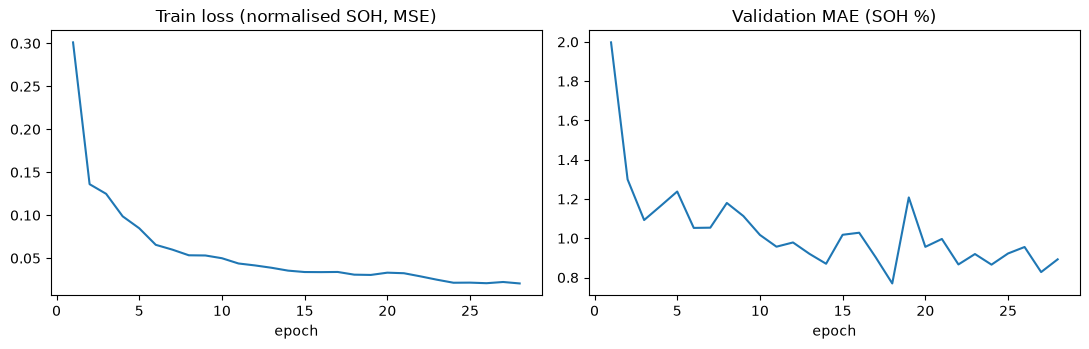

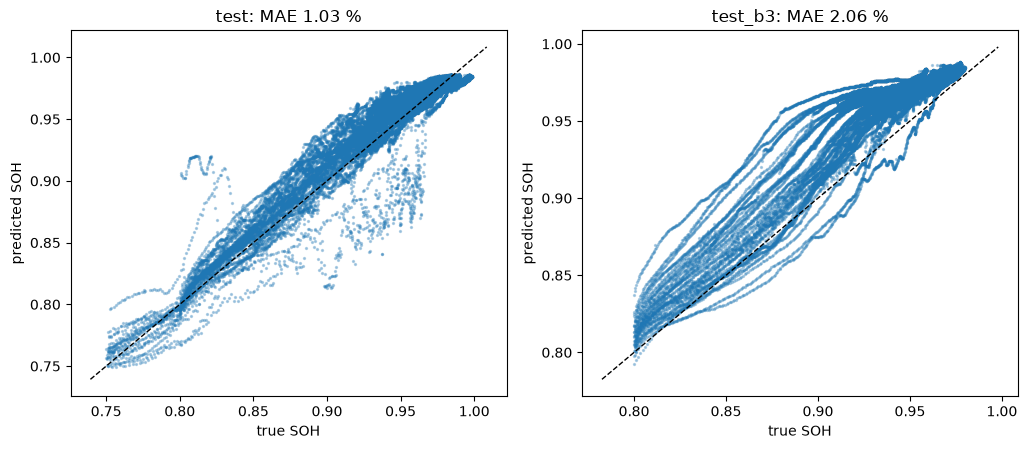

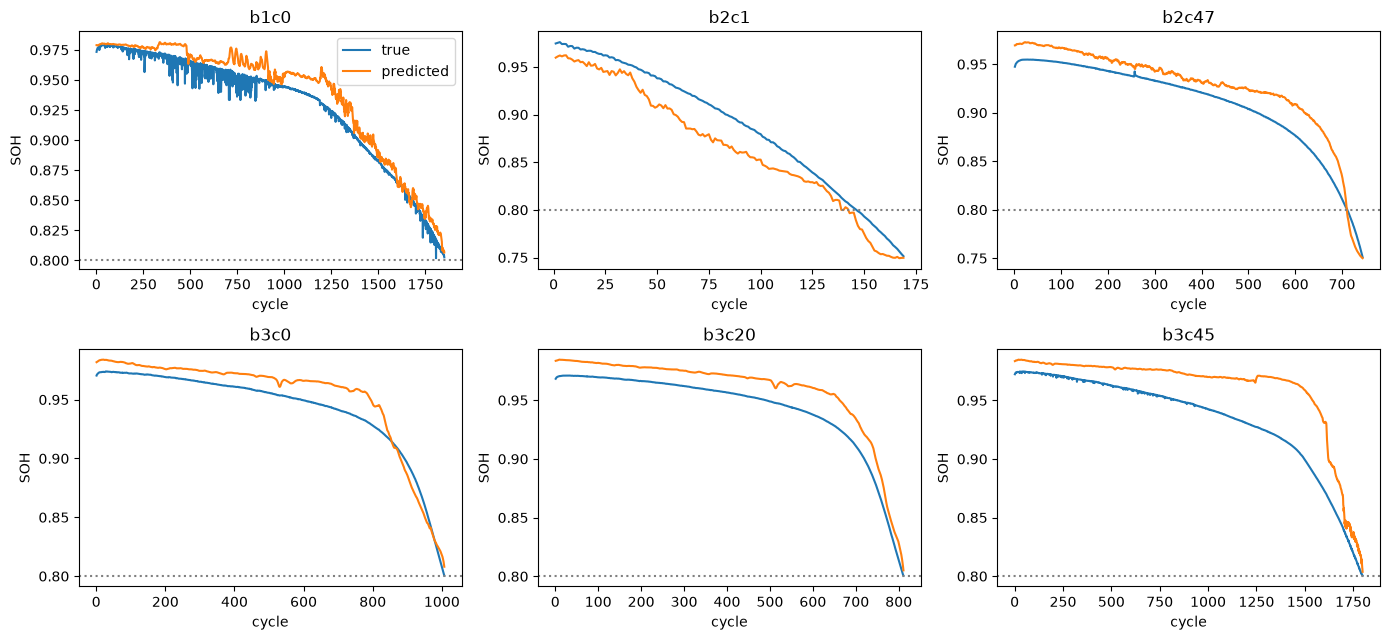

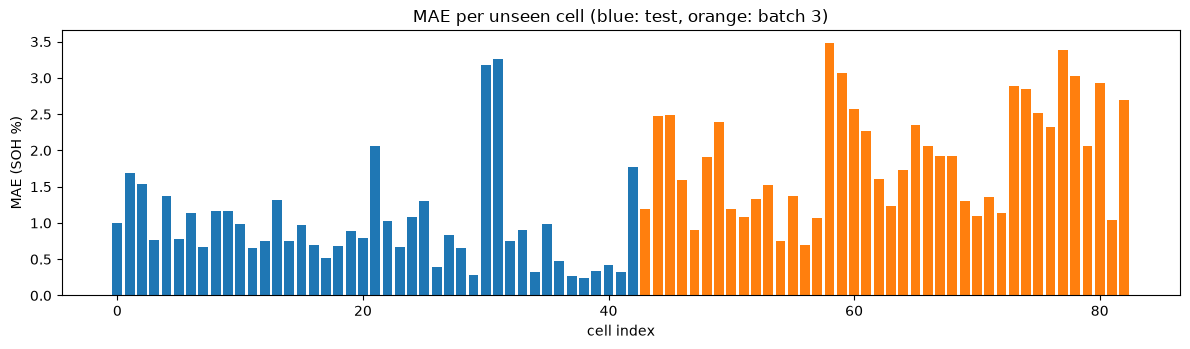

worst cell: b3c16 (3.48 %)


In [10]:
preds = {k: predict(model, dev[k]) for k in dev}
results["CNN + GRU"] = {k: metrics(sets[k]["y"], preds[k]) for k in dev}

table_mae = pd.DataFrame({m: {s: r[s]["MAE_%"] for s in r} for m, r in results.items()}).T
table_rmse = pd.DataFrame({m: {s: r[s]["RMSE_%"] for s in r} for m, r in results.items()}).T
print("MAE in SOH percentage points (lower is better)")
print(table_mae.round(3))
print("\nRMSE in SOH percentage points")
print(table_rmse.round(3))
with open(OUT / "metrics.json", "w") as fh:
    json.dump(results, fh, indent=2)

# learning curve
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h["epoch"], h["train_loss"]); ax[0].set(title="Train loss (normalised SOH, MSE)", xlabel="epoch")
ax[1].plot(h["epoch"], h["val_MAE_%"]); ax[1].set(title="Validation MAE (SOH %)", xlabel="epoch")
plt.tight_layout(); plt.savefig(OUT / "fig1_learning_curve.png", dpi=150); plt.show()

# predicted vs true
test_sets = [k for k in ("test", "test_b3") if k in dev]
fig, ax = plt.subplots(1, len(test_sets), figsize=(5.2 * len(test_sets), 4.6), squeeze=False)
for a, k in zip(ax[0], test_sets):
    a.scatter(sets[k]["y"], preds[k], s=2, alpha=0.3)
    lim = [min(sets[k]["y"].min(), preds[k].min()) - 0.01, max(sets[k]["y"].max(), preds[k].max()) + 0.01]
    a.plot(lim, lim, "k--", lw=1)
    a.set(title=f"{k}: MAE {results['CNN + GRU'][k]['MAE_%']:.2f} %", xlabel="true SOH", ylabel="predicted SOH")
plt.tight_layout(); plt.savefig(OUT / "fig2_pred_vs_true.png", dpi=150); plt.show()

# SOH trajectories of a few unseen cells
picks = [(k, j) for k in test_sets for j in np.linspace(0, len(split[k]) - 1, 3).astype(int)]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), squeeze=False)
for a, (k, j) in zip(axes.ravel(), picks):
    m = sets[k]["cell_pos"] == j
    a.plot(sets[k]["cycle"][m], sets[k]["y"][m], label="true")
    a.plot(sets[k]["cycle"][m], preds[k][m], label="predicted")
    a.axhline(EOL_SOH, color="grey", ls=":")
    a.set(title=split[k][j], xlabel="cycle", ylabel="SOH")
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(OUT / "fig3_trajectories.png", dpi=150); plt.show()

# error per unseen cell
rows = []
for k in test_sets:
    for j, cid in enumerate(split[k]):
        m = sets[k]["cell_pos"] == j
        rows.append({"cell": cid, "set": k, "MAE_%": np.abs(preds[k][m] - sets[k]["y"][m]).mean() * 100})
per_cell = pd.DataFrame(rows)
per_cell.to_csv(OUT / "per_cell_mae.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(range(len(per_cell)), per_cell["MAE_%"], color=["C0" if s == "test" else "C1" for s in per_cell["set"]])
ax.set(title="MAE per unseen cell (blue: test, orange: batch 3)", xlabel="cell index", ylabel="MAE (SOH %)")
plt.tight_layout(); plt.savefig(OUT / "fig4_error_per_cell.png", dpi=150); plt.show()
worst = per_cell.loc[per_cell["MAE_%"].idxmax()]
print(f"worst cell: {worst['cell']} ({worst['MAE_%']:.2f} %)")

## 9. Real-time demo: one cycle in, one SOH out

cell b1c0: 1826 cycles streamed one at a time
max |streamed - batch prediction| = 4.48e-08
MAE vs true SOH = 1.00 % | latency 2.0 ms per cycle


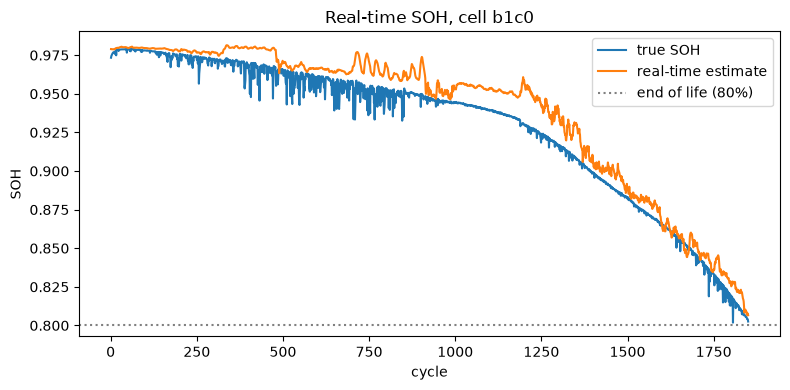

In [11]:
class RealTimeSOH:
    # call update() at the end of every cycle; it keeps the last HISTORY cycles and returns the SOH estimate
    def __init__(self, model, norm, W=HISTORY):
        self.model, self.norm, self.W = model.eval(), norm, W
        self.curves, self.scalars = deque(maxlen=W), deque(maxlen=W)

    def update(self, qdlin_row, tdlin_row, scalars_row):
        c = curve_feats(qdlin_row[None], tdlin_row[None])[0]
        c = ((c - self.norm["c_mean"]) / self.norm["c_std"]).astype(np.float32)
        s = np.nan_to_num((scalars_row - self.norm["s_mean"]) / self.norm["s_std"]).astype(np.float32)
        self.curves.append(c)
        self.scalars.append(s)
        pad = self.W - len(self.curves)
        xc = np.stack([self.curves[0]] * pad + list(self.curves))[None]
        xs = np.stack([self.scalars[0]] * pad + list(self.scalars))[None]
        with torch.no_grad():
            y = self.model(torch.as_tensor(xc, device=DEVICE), torch.as_tensor(xs, device=DEVICE)).item()
        return y * self.norm["y_std"] + self.norm["y_mean"]


demo_set = "test" if "test" in dev else test_sets[0]
demo_cid = split[demo_set][0]
cell, arr = cells[demo_cid], arrays_raw[demo_cid]

estimator = RealTimeSOH(model, norm)
latency, stream = [], []
for k in range(len(arr["soh"])):
    t1 = time.time()
    stream.append(estimator.update(cell["Qdlin"][k], cell["Tdlin"][k], arr["scalars"][k]))
    latency.append(time.time() - t1)
stream = np.array(stream)

batch_pred = preds[demo_set][sets[demo_set]["cell_pos"] == 0]
print(f"cell {demo_cid}: {len(stream)} cycles streamed one at a time")
print(f"max |streamed - batch prediction| = {np.abs(stream - batch_pred).max():.2e}")
print(f"MAE vs true SOH = {np.abs(stream - arr['soh']).mean() * 100:.2f} % | latency {np.mean(latency) * 1000:.1f} ms per cycle")

plt.figure(figsize=(8, 4))
plt.plot(arr["cycle"], arr["soh"], label="true SOH")
plt.plot(arr["cycle"], stream, label="real-time estimate")
plt.axhline(EOL_SOH, color="grey", ls=":", label="end of life (80%)")
plt.xlabel("cycle"); plt.ylabel("SOH"); plt.title(f"Real-time SOH, cell {demo_cid}"); plt.legend()
plt.tight_layout(); plt.savefig(OUT / "fig5_realtime_demo.png", dpi=150); plt.show()

## 10. Timing summary

In [12]:
for k, v in TIMES.items():
    print(f"{k:12s} {v / 60:6.1f} min")
print(f"{'total':12s} {sum(TIMES.values()) / 60:6.1f} min   (loading and cleaning are ~0 on a re-run because of the cache)")
print("outputs in:", OUT.resolve())

1_load_mat      0.0 min
2_clean         0.0 min
3_train         1.3 min
total           1.3 min   (loading and cleaning are ~0 on a re-run because of the cache)
outputs in: /Users/manik/Battery_project/soh_outputs
